In [1]:
# Task 1, Task 2 and Task 3: Install the libraries needed for cleaning, visualisation and LDA topic modelling

!pip -q install wordcloud pyLDAvis gensim

In [2]:
# Task 1: Import required libraries and download NLTK resources for tokenization, stop-word removal and lemmatization

import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

sns.set_style("whitegrid")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [3]:
# Task 1: Load the health-related headlines dataset directly from GitHub and view its first rows

url = "https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Health_Related_Headlines_Dataset.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (39405, 5)


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management


In [4]:
# Task 1: Inspect dataset columns and check for missing values before cleaning

print(df.columns)
df.isnull().sum()

Index(['Date', 'Source', 'Headlines', 'Teaser', 'Category'], dtype='object')


,0
Date,0
Source,0
Headlines,0
Teaser,0
Category,0


In [5]:
# Task 1: Combine Headlines and Teaser columns to create one text field for NLP analysis

df = df.dropna(subset=["Headlines"]).drop_duplicates().copy()

df["text"] = (
    df["Headlines"].fillna("") + " " + df["Teaser"].fillna("")
)

df[["Headlines", "Teaser", "text"]].head()

,Headlines,Teaser,text
0,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Special Report: Adult Vaccines -- New ACIP Rec...
1,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Combined Internet and Telephone Intervention M...
2,Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Link Between Parental Alcoholism and Childhood...
3,Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Methadone Dose in the Treatment of Opiate Depe...
4,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Magnet Treatment Had No Beneficial Effect on P...


In [6]:
# Task 1: Create a function for lowercasing, punctuation removal, tokenization, stop-word removal and lemmatization

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation, numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize text into words
    tokens = word_tokenize(text)

    # Remove stop words, short words, then lemmatize remaining words
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return cleaned_tokens

In [7]:
# Task 1: Apply the cleaning function to all health-related text records

df["cleaned_tokens"] = df["text"].apply(clean_text)

# Convert cleaned tokens back into readable text
df["cleaned_text"] = df["cleaned_tokens"].apply(lambda words: " ".join(words))

df.head()

,Date,Source,Headlines,Teaser,Category,text,cleaned_tokens,cleaned_text
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization,Special Report: Adult Vaccines -- New ACIP Rec...,"[special, report, adult, vaccine, new, acip, r...",special report adult vaccine new acip recommen...
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction,Combined Internet and Telephone Intervention M...,"[combined, internet, telephone, intervention, ...",combined internet telephone intervention may f...
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction,Link Between Parental Alcoholism and Childhood...,"[link, parental, alcoholism, childhood, mood, ...",link parental alcoholism childhood mood disord...
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction,Methadone Dose in the Treatment of Opiate Depe...,"[methadone, dose, treatment, opiate, dependenc...",methadone dose treatment opiate dependence epi...
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management,Magnet Treatment Had No Beneficial Effect on P...,"[magnet, treatment, beneficial, effect, patien...",magnet treatment beneficial effect patient chr...


In [8]:
# Task 1: Display a few original and cleaned healthcare text samples

df[["Headlines", "cleaned_text"]].sample(5, random_state=42)

,Headlines,cleaned_text
33232,US Opioid Overdose Epidemic Getting Worse,opioid overdose epidemic getting worse latest ...
20645,"FDA Strengthens NSAID Warning for Heart, Stro...",fda strengthens nsaid warning heart stroke ris...
4334,Quantitative In Vitro and In Vivo Pharmacologi...,quantitative vitro vivo pharmacological profil...
14291,Exclusive: NewLink Says Ebola Vaccine Trial Co...,exclusive newlink say ebola vaccine trial coul...
4345,Is Dextromethorphan a Concern for False Positi...,dextromethorphan concern false positive urine ...


In [9]:
# Task 2: Calculate the frequency of all cleaned health-related words

from collections import Counter

all_words = [word for tokens in df["cleaned_tokens"] for word in tokens]

word_frequency = Counter(all_words)

print("Top 20 most frequent words:")
print(word_frequency.most_common(20))

Top 20 most frequent words:
[('patient', 12924), ('new', 7867), ('risk', 7563), ('study', 6860), ('drug', 6552), ('treatment', 5767), ('cancer', 5609), ('pain', 5604), ('use', 4940), ('may', 4795), ('disease', 4045), ('therapy', 3477), ('trial', 3068), ('vaccine', 2964), ('care', 2848), ('fda', 2756), ('opioid', 2751), ('year', 2610), ('health', 2581), ('child', 2434)]


/tmp/ipykernel_697/3455177850.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=words, palette="viridis")


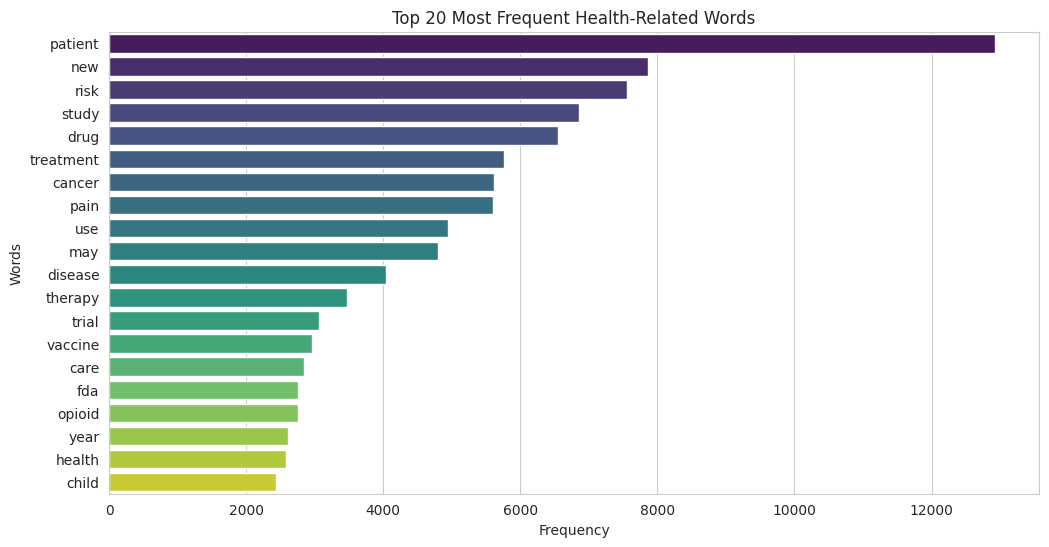

In [10]:
# Task 2: Create a bar chart showing the top 20 most frequent health-related words

top_20_words = word_frequency.most_common(20)

words = [item[0] for item in top_20_words]
counts = [item[1] for item in top_20_words]

plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=words, palette="viridis")

plt.title("Top 20 Most Frequent Health-Related Words")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.show()

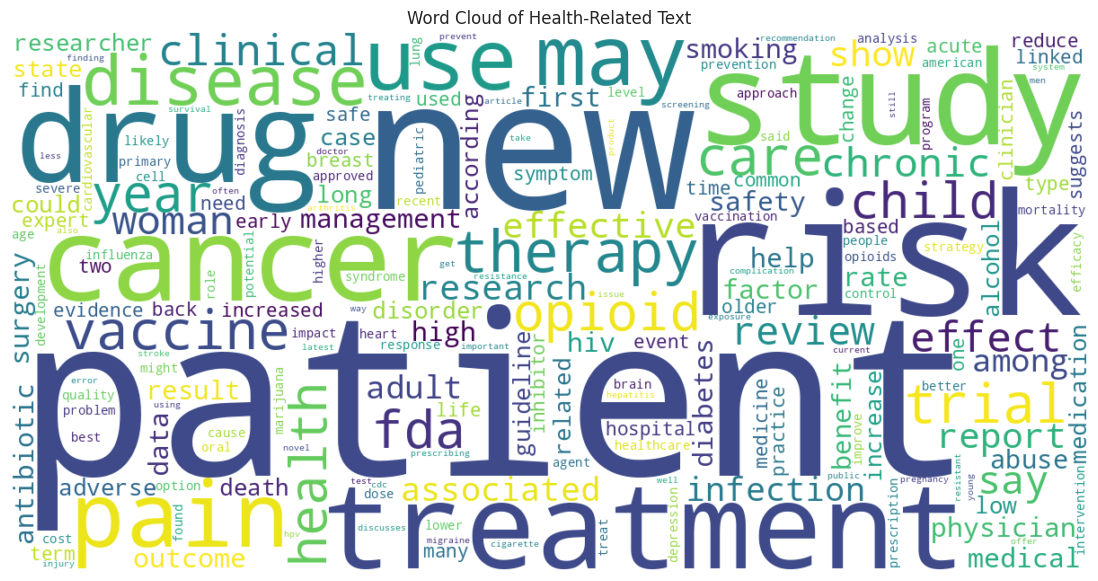

In [11]:
# Task 2: Generate a word cloud of the most common health-related terms

from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis"
).generate_from_frequencies(word_frequency)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Text")
plt.show()

In [12]:
# Task 3: Create a dictionary and document-term matrix needed for LDA topic modelling

from gensim import corpora

dictionary = corpora.Dictionary(df["cleaned_tokens"])

# Keep useful words and remove extremely rare or extremely common words
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(tokens) for tokens in df["cleaned_tokens"]]

print("Number of unique words in dictionary:", len(dictionary))
print("Number of documents in corpus:", len(corpus))

Number of unique words in dictionary: 9342
Number of documents in corpus: 38894


In [13]:
# Task 3: Train an LDA model to identify five dominant health-related topics

from gensim.models import LdaModel

num_topics = 5

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    random_state=42,
    passes=10,
    alpha="auto",
    per_word_topics=True
)

In [14]:
# Task 3: Display the top 5 important words for each health-related topic found by LDA

topics = lda_model.print_topics(num_topics=num_topics, num_words=5)

for topic_number, topic_words in topics:
    print(f"Topic {topic_number + 1}: {topic_words}\n")

Topic 1: 0.052*"drug" + 0.034*"opioid" + 0.020*"fda" + 0.016*"infection" + 0.012*"said"

Topic 2: 0.033*"cancer" + 0.021*"patient" + 0.020*"treatment" + 0.018*"therapy" + 0.017*"study"

Topic 3: 0.023*"health" + 0.018*"child" + 0.018*"vaccine" + 0.012*"use" + 0.012*"hiv"

Topic 4: 0.049*"risk" + 0.023*"study" + 0.022*"patient" + 0.020*"may" + 0.013*"disease"

Topic 5: 0.033*"patient" + 0.023*"pain" + 0.015*"care" + 0.013*"new" + 0.012*"treatment"



In [15]:
# Task 3: Create an interactive pyLDAvis visualization for the LDA topic model

import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

lda_visualisation = gensimvis.prepare(
    lda_model,
    corpus,
    dictionary,
    sort_topics=False
)

pyLDAvis.display(lda_visualisation)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
